# Direct R+C fit and MCMC — ID6170 example

Use the **grism** kernel and run top to bottom. Change the source and explicit settings below for another galaxy.

One shared, freely varying positive emission map produces both grism images. We compare those predictions with the original R and C pixels. First find a starting fit, then run **joint MCMC of the kinematics and emission map** for uncertainties.

For this example, inclination is sampled with a **75° ± 5° Gaussian prior** and the source center stays fixed at **(40.25, 41.0) pixels**. This prototype has no explicit PSF or intrinsic dispersion; reported intervals remain conditional on those choices and the fixed center.


In [1]:
from pathlib import Path
import os, sys, importlib, logging
import matplotlib.pyplot as plt
import torch
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "dingo").is_dir() else Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"
OVERRIDE = True   # Replace only the named run prepared below
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
torch.set_num_threads(min(4, os.cpu_count() or 1))
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import direct_source, injection_flexible, direct_workflow as direct
for module in (direct_source, injection_flexible, direct):
    importlib.reload(module)
# Reload optional MCMC modules only if this kernel has used them before.
for name in ("dingo.direct_posterior_model", "dingo.direct_sampling", "dingo.direct_posterior_review"):
    if name in sys.modules:
        importlib.reload(sys.modules[name])
print("Profile-fit device:", DEVICE)
print("Output root:", OUTPUT_ROOT)

Profile-fit device: cuda
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Choose the source and starting values

`prepare` reads `ID6170/image.fits`, `R.fits`, `C.fits`, and its calibration metadata. It does not require a previous fit. Imaging is displayed only; it does not prescribe the gas morphology. The center and offsets are zero-based pixels, and supplied angles are degrees.

The cyan crosses show where the fixed kinematic center projects into the raw R and C images at the starting registration. The R projection can move as registration is fitted.

The existing ID6170 C image contains three large negative pixels near (46,61), (40,55), and (35,49), outside its previously cleaned circle. Inspect their residuals; they are included in this experiment.

ID6170: center fixed at (40.25, 41.0) pixels; fitted i prior 75 +/- 5 degrees.
R/C noise: {'R': 0.0034141347629099, 'C': 0.003515137827137167}
Saving to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_joint_i75s5_v450_v1


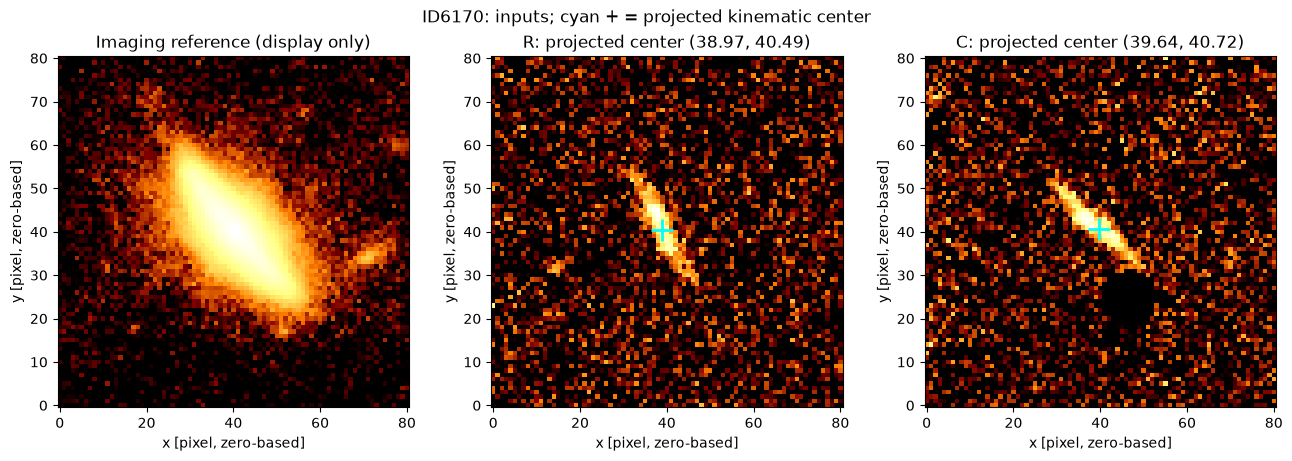

In [2]:
run = direct.prepare(
    6170,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name="direct_joint_i75s5_v450_v1",
    center=(40.25, 41.0),
    inclination_mean=75.0,
    inclination_sigma=5.0,
    start_inclination=75.0,
    start_velocity=450.0,
    start_turnover=10.09,
    start_pa=286.64,
    start_offset=(1.0625, 0.2852),
    max_velocity=1000.0,
    device=DEVICE,
    overwrite=OVERRIDE,
)
fig = direct.show_inputs(run)
display(fig)
plt.close(fig)

## 2. Find a starting fit

The fitter varies velocity, turnover radius, orientation, R x/y registration, and inclination. For each trial, it fits a shared emission map from R+C, with no Sérsic shape or smoothing prior. R and C use separate background-noise estimates.

The progress bar counts trial evaluations; `max_evaluations` is a budget, not an MCMC chain length. Best-fit checkpoints and `run_info.txt` are saved as the score improves. Sparse map solves use CPU linear algebra even when the coordinate model uses CUDA.

In [3]:
fit_result = direct.fit(run, max_evaluations=150, progress=True)

Free-map fit evaluations:   0%|          | 0/150 [00:00<?, ?it/s]

Saved best fit: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_joint_i75s5_v450_v1
Optimizer: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Gradient criterion met: False


## 3. Inspect the starting fit

These panels compare the **original input, direct prediction, and residual divided by noise** for each grism. Residual colors saturate at ±5; the label counts pixels beyond that display range. No finite pixels are omitted from fitting.

The table and figures use the same saved best-fit parameter vector. This starting-fit curve has no error band. The MCMC block below produces the posterior intervals. `V_inf` is asymptotic velocity; `V_at_R_t = V_inf / 2` is the velocity at the fitted turnover radius.

To reopen without fitting, call `direct.show_results(OUTPUT_ROOT / "6170" / "direct_joint_i75s5_v450_v1")` in place of the first line below. All outputs are saved inside that run folder.

Status: completed Optimizer: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Gradient criterion met: False Inner optimality: 1.7880338756912778e-07
This table contains profile-fit values. Use sample and show_posterior for joint MCMC intervals.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_joint_i75s5_v450_v1


,value,unit
V_inf,489.019636,km/s
R_t,11.685612,pixel
cutout_PA,289.218683,deg
R_dx,1.400655,pixel
R_dy,-0.223332,pixel
inclination,74.269908,deg
V_at_R_t,244.509818,km/s


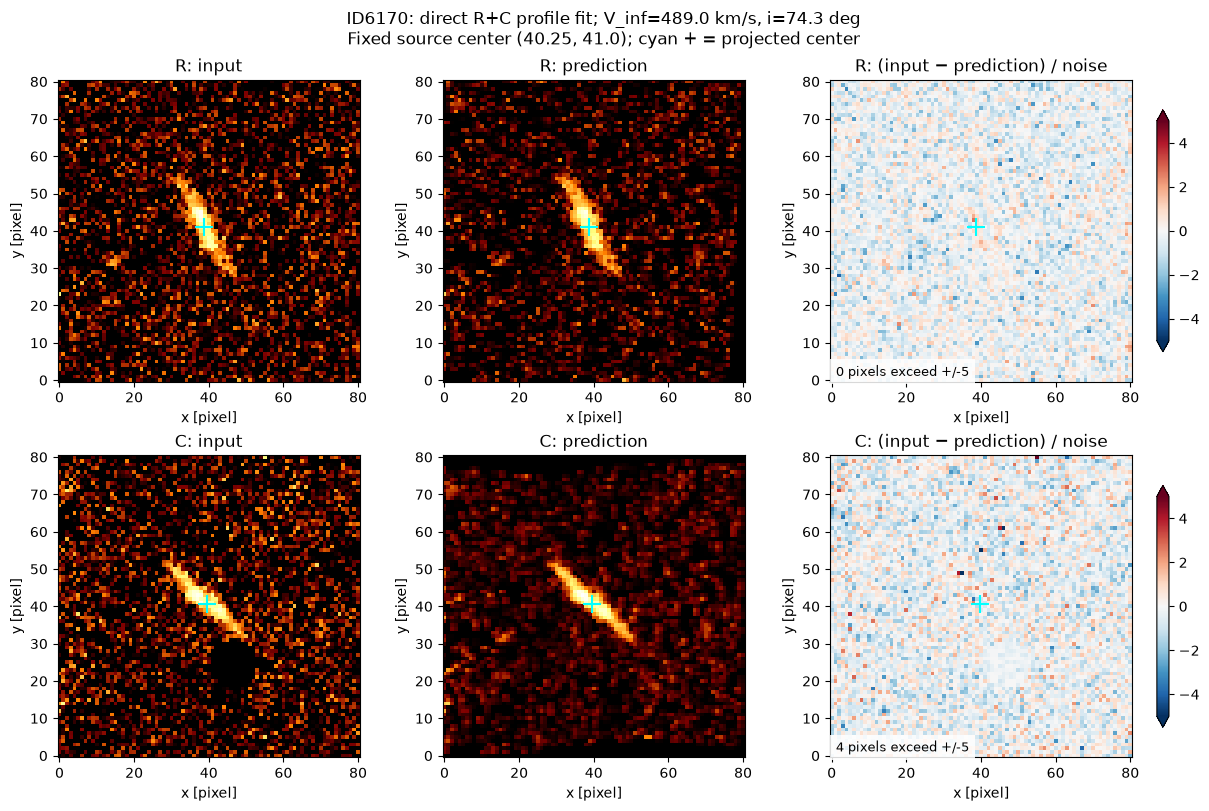

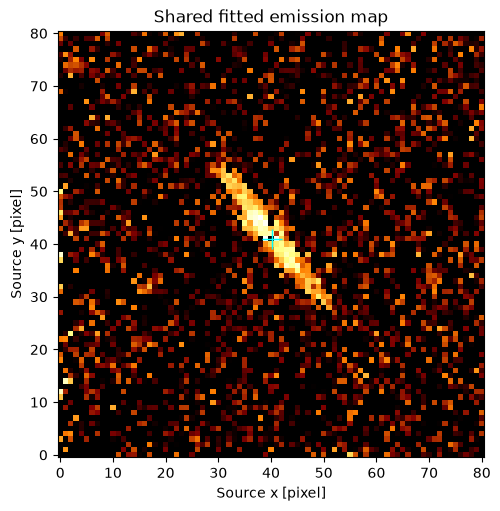

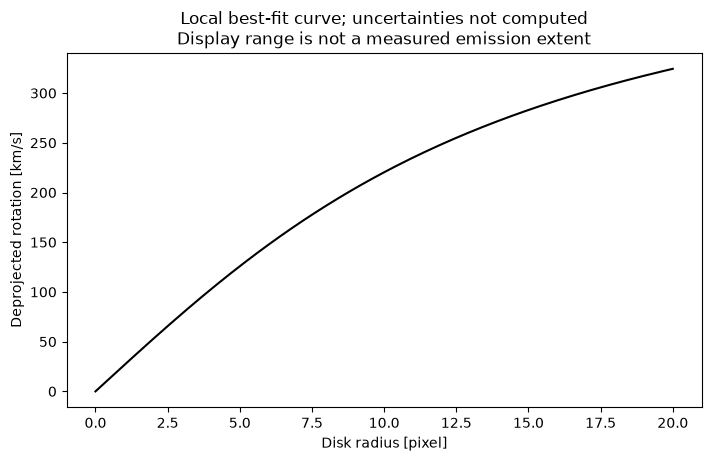

In [4]:
views = direct.show_results(run)
display(views["summary"])
for name in ("residuals", "emission", "rotation_curve"):
    display(views[name])
    plt.close(views[name])

## 4. Run MCMC

`direct.sample` samples velocity, turnover radius, orientation, R registration, inclination, **and the shared emission pixels together**. It uses **NumPyro NUTS / JAX** and prints the actual CPU/GPU device. The six-parameter corner plot leaves out the thousands of brightness parameters, but they are sampled and their mixing is checked.

Each pixel gets an independent positive half-normal brightness prior, with no Sérsic shape or spatial smoothing. `emission_prior_scale=None` selects **10 × the larger of the positive observed peak and noise**, in FITS intensity units. The exact scale is printed and saved. This is an adjustable assumption; compare scales before using errors for a paper.

The progress bars count warmup and retained draws **per chain**. Compilation has a heartbeat message; checkpoints save every 25 steps. Start with the settings below; short tests can use `warmup=100, draws=100`, but are not science runs. Check convergence, not just step count.

To continue an interrupted MCMC, keep the same `run` and settings, use `resume=True, overwrite=False`, and rerun **only this block**. `draws` is the desired total. Do not rerun preparation with `OVERRIDE=True` when resuming: that intentionally starts the named run fresh.

After a kernel restart, run the imports and recover the handle with `run = direct.load_run(OUTPUT_ROOT / "6170" / "direct_joint_i75s5_v450_v1")`, then call MCMC with `resume=True, overwrite=False` and the original settings. A partial retained checkpoint can also be plotted directly by passing its folder to `direct.show_posterior`.


In [5]:
posterior_path = direct.sample(
    run,
    warmup=500,
    draws=1000,
    chains=4,
    emission_prior_scale=None,
    target_accept=0.9,
    max_tree_depth=8,
    checkpoint_every=25,
    seed=42,
    device="auto",        # JAX selects GPU when available; prints actual device
    progress=True,
    overwrite=OVERRIDE,
    resume=False,
)


MCMC: 4 chains; 500 warmup + 1000 retained draws per chain.
JAX device: cuda:0; float64 target; 6561 emission pixels sampled.
Pixel prior: independent HalfNormal(scale=0.402402); no spatial shape prior.
Saving to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_joint_i75s5_v450_v1/posterior.npz
Initializing NUTS (first JAX compilation can take a while)


Warmup:   0%|          | 0/500 [00:00<?, ?step/chain/s]

MCMC:   0%|          | 0/1000 [00:00<?, ?step/chain/s]

MCMC saved: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/direct_joint_i75s5_v450_v1/posterior.npz
Convergence checks passed: False


## 5. Display the uncertainties

This block **only reads saved results**. The table and black contours show pooled medians with 16th–84th percentile intervals. Check the chain traces, divergences, R̂ and effective sample sizes before trusting those intervals. Failed checks remain visible and do not prevent inspection.

The residual panels use **one actual joint draw near the pooled kinematic median**, with its matching emission map; their title gives that draw's velocity. The rotation-curve band propagates the sampled velocity and turnover radius. The plotted radius range does not establish the measured emission extent.

For results-only viewing after restarting the kernel, run the imports and pass the run folder to `direct.show_posterior`, for example `direct.show_posterior(OUTPUT_ROOT / "6170" / "direct_joint_i75s5_v450_v1")`. Preparation, fitting, and sampling are unnecessary for reopening.


Posterior: provisional: mixing checks did not pass
Retained draws: 4 chains × 1000 steps per chain
Divergences: 0 Max-depth fraction: 0.0
Kinematic diagnostics (rank R-hat, bulk ESS, tail ESS):
  V_inf: 1.2572545039905494, 12.481233412533008, 354.1403640191493
  R_t: 1.0760936773268224, 45.722157055374964, 226.71398707547357
  cutout_PA: 1.2324017216314536, 13.642473049357298, 17.832569486441134
  R_dx: 1.736452275019207, 6.287286839707165, 142.65110251656577
  R_dy: 1.7404662752364508, 6.18018149388323, 161.41246563805936
  inclination: 1.1695483442726926, 16.41510745526122, 90.3128377058473
Numerical convergence checks did not pass; displayed intervals are provisional.
Residual panels use one actual joint draw; table/corner/rotation intervals pool all chains.
Conditional on the fixed kinematic center, calibration, pixel grid, independent HalfNormal emission-pixel prior and independent Gaussian input noise. No PSF or intrinsic velocity dispersion is modeled. Passing these numerical ch

,median,minus_16th,plus_84th,unit
parameter (all chains pooled),,,,
V_inf,179.484310,17.213910,17.080516,km/s
R_t,3.023060,0.524363,0.652290,pixel
cutout_PA,306.503469,0.902445,1.009480,deg
R_dx,1.482500,0.107848,0.393448,pixel
R_dy,-0.222613,0.502255,0.505958,pixel
inclination,79.966748,1.469475,1.061546,deg
V_at_R_t,89.742155,8.606955,8.540258,km/s


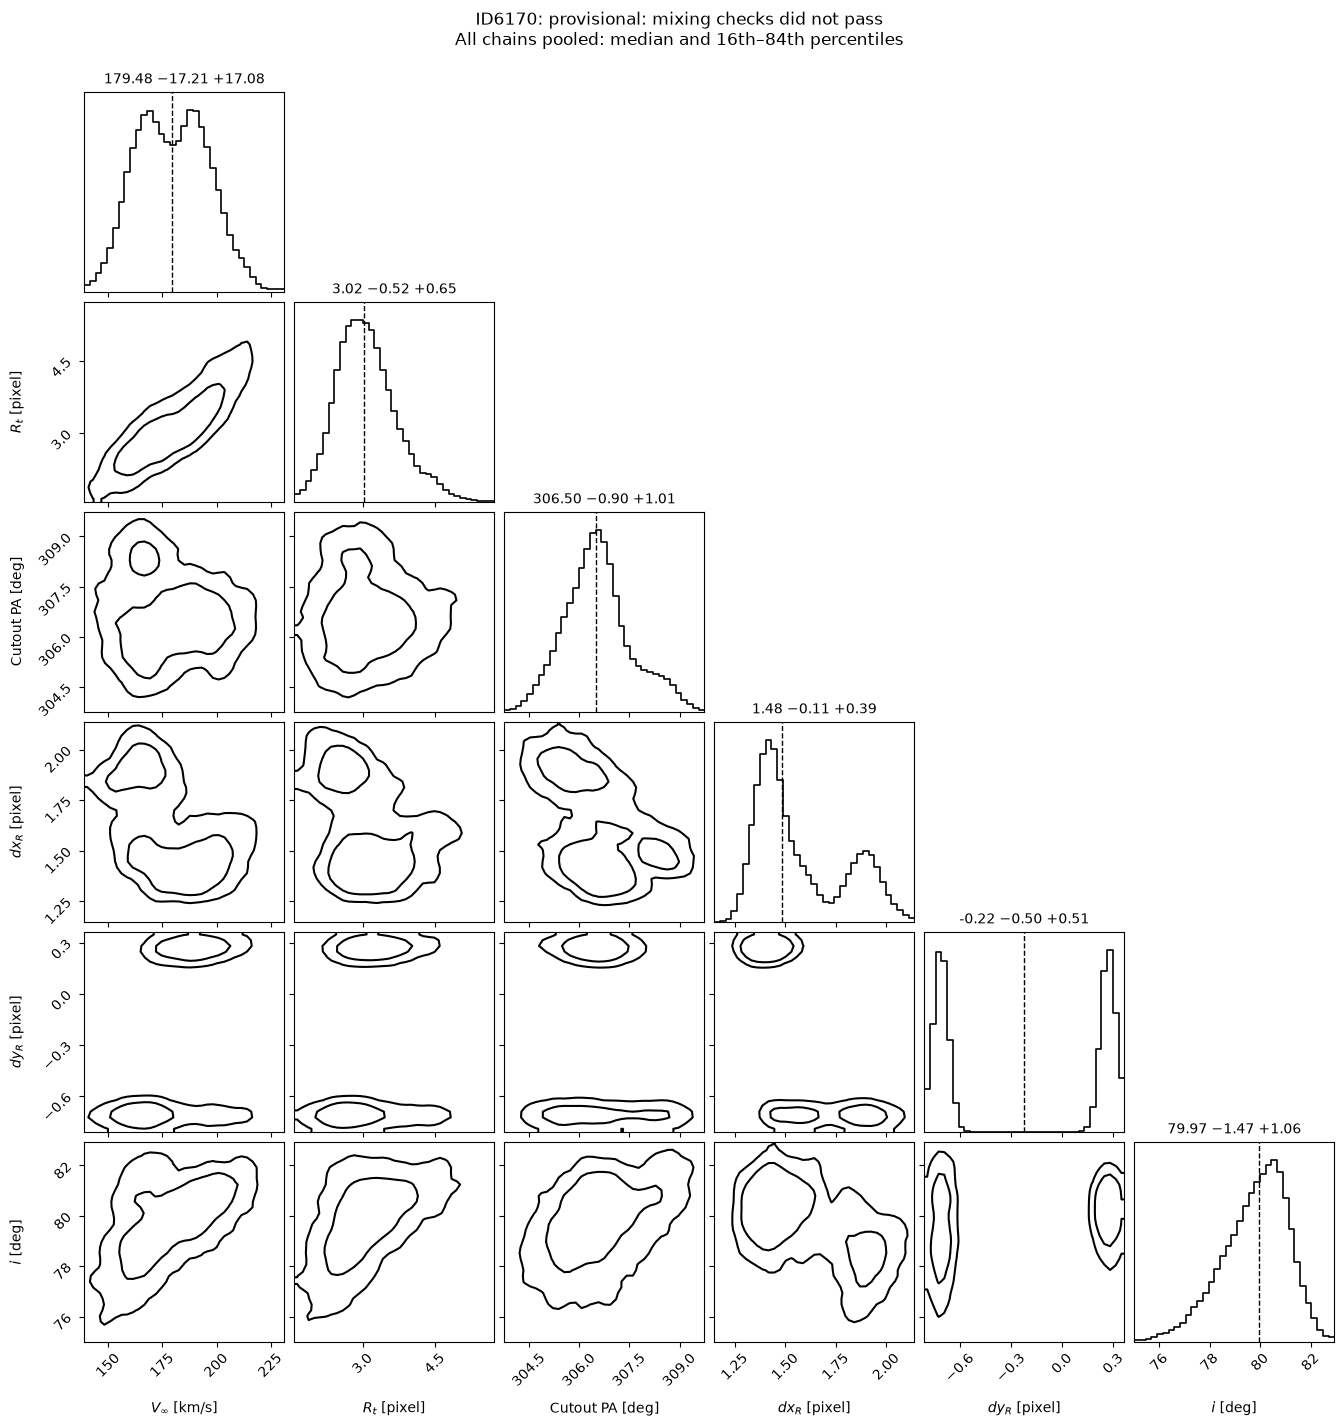

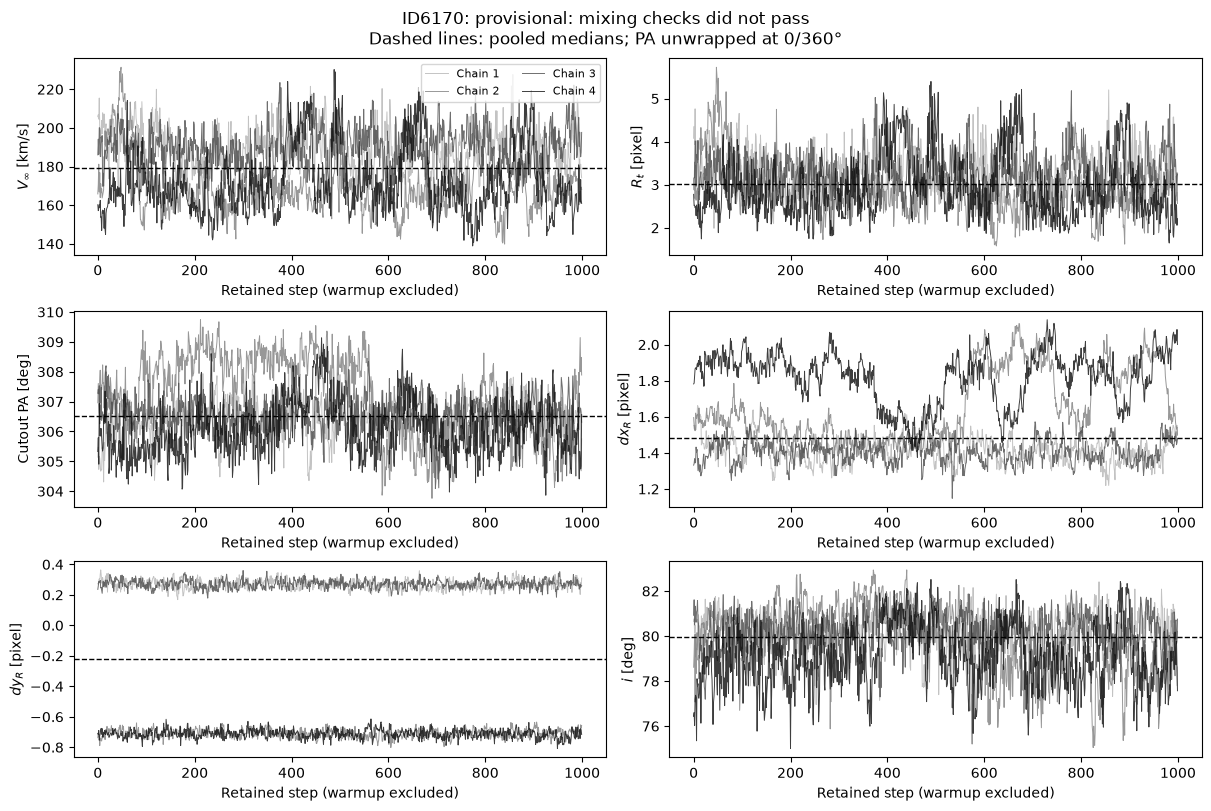

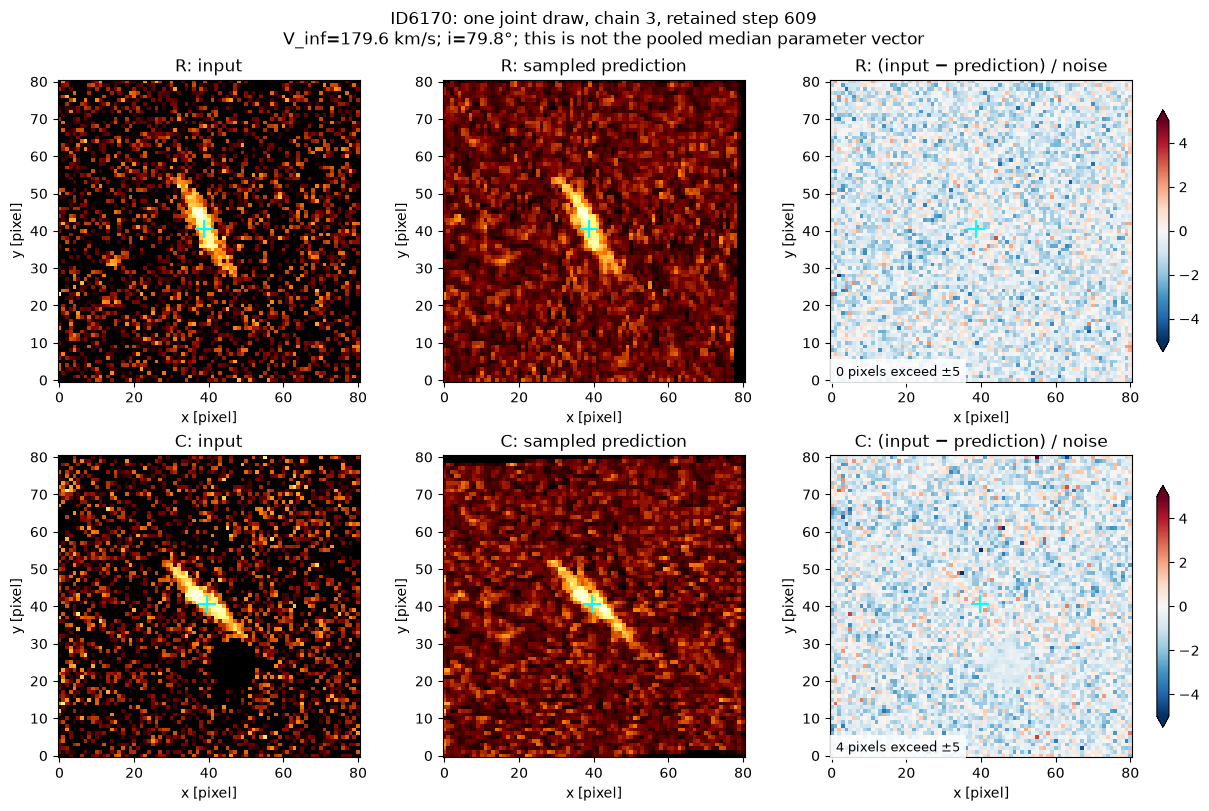

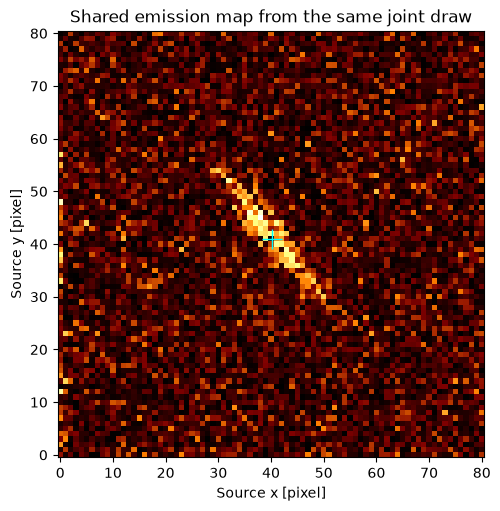

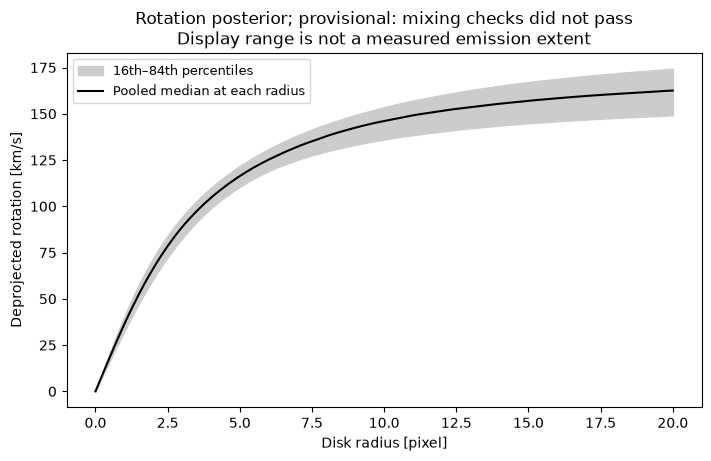

In [6]:
posterior_views = direct.show_posterior(run)
display(posterior_views["summary"])
for name in ("corner", "traces", "residuals", "emission", "rotation_curve"):
    display(posterior_views[name])
    plt.close(posterior_views[name])


To try another source or configuration, copy the preparation, fit and sample calls with a new handle such as `run_b` and a different `run_name`. Each run writes `fit.npz`, `posterior.npz`, diagnostics, plots and `run_info.txt` into its own directory. The pixel-map draws can make `posterior.npz` roughly 100 MB for four chains × 1000 draws of an 81 × 81 map.
